# Partial differential equations 1: The heat equation

*Learning path: partial differential equations, part 1 of 3.* [Index](README.md) · Previous: [Held, simplify, eval](00-held-simplify-eval.ipynb) · Next: [Waves on a string](02-waves-on-a-string.ipynb)

Heat one end of a metal rod and the warmth creeps along it. A drop of ink spreads through a glass of water. A rumour
spreads through a town, a price through a market. All of these follow the **heat equation**, which Joseph Fourier
wrote down in 1807 and solved in his *Analytical Theory of Heat* (1822). To solve it he invented Fourier series, one
of the most useful ideas in mathematics. The same equation reappears in probability (it describes Brownian motion), in
finance (the Black–Scholes equation is a heat equation in disguise) and in image processing (blurring a photo).

This lesson solves it the way a computer does: chop the rod into small pieces and time into small steps, and update
the temperature step by step. Along the way you will meet the most important trap of numerical computing,
**instability**, and the method that avoids it.

**Who this is for.** Students who know derivatives and matrix multiplication
([linear algebra 1](../linear-algebra/01-vectors-and-matrices.ipynb)); the
[differential equations](../differential-equations/README.md) path helps but is not needed.

**What you will be able to do afterwards:**

1. explain where the heat equation comes from and what each term means;
2. turn it into a step-by-step update with a matrix, and run it;
3. recognise an unstable scheme and state the stability condition $r \le 1/2$;
4. solve heat problems with `heat`, with fixed or insulated ends and heat sources, and show them with `pdeplot`;
5. check a numerical solution against Fourier's exact series solution.

Plan about 60 minutes. Each section ends with a **Try this**; exercises, hints and answers are at the end.

## 1. Where the equation comes from

Cut a rod of length 1 into small pieces of length $h$, and let $u_i$ be the temperature of piece $i$. Heat flows from
hot to cold, at a rate proportional to the temperature difference (Newton's law of cooling). Piece $i$ receives heat
from its left neighbour at a rate proportional to $u_{i-1} - u_i$ and from its right neighbour at a rate proportional
to $u_{i+1} - u_i$. Adding the two:

$$\frac{du_i}{dt} = \frac{k}{h^2}\,(u_{i-1} - 2u_i + u_{i+1}).$$

The bracket is $h^2$ times the second difference, which tends to the second derivative as $h \to 0$. So the rod obeys

$$u_t = k\, u_{xx},$$

where $u(x, t)$ is the temperature at position $x$ and time $t$, and $k$ (the **diffusivity**) says how fast heat
spreads. In words: *a point warms up when it is colder than the average of its neighbours*. Where the temperature
curve bends upwards ($u_{xx} > 0$) the point heats up; where it bends downwards it cools.

To compute, we also step time forward by small steps $\Delta t$:

$$u_i^{\text{new}} = u_i + r\,(u_{i-1} - 2u_i + u_{i+1}), \qquad r = \frac{k\,\Delta t}{h^2}.$$

This is the **explicit scheme**. With the ends held at temperature 0, the new temperatures are the old ones times a
matrix $A$ with $1 - 2r$ on the diagonal and $r$ next to it. Take $k = 1$, ten pieces ($h = 1/10$) and $r = 2/5$:

In [1]:
n = 10;
h = 1/n;
r = 2/5;
A = zeros(n - 1, n - 1);
for i = 1:n - 1
  A(i, i) = 1 - 2*r;
  if i > 1
    A(i, i - 1) = r;
  end
  if i < n - 1
    A(i, i + 1) = r;
  end
end
A

[1/5, 2/5,   0,   0,   0,   0,   0,   0,   0;
 2/5, 1/5, 2/5,   0,   0,   0,   0,   0,   0;
   0, 2/5, 1/5, 2/5,   0,   0,   0,   0,   0;
   0,   0, 2/5, 1/5, 2/5,   0,   0,   0,   0;
   0,   0,   0, 2/5, 1/5, 2/5,   0,   0,   0;
   0,   0,   0,   0, 2/5, 1/5, 2/5,   0,   0;
   0,   0,   0,   0,   0, 2/5, 1/5, 2/5,   0;
   0,   0,   0,   0,   0,   0, 2/5, 1/5, 2/5;
   0,   0,   0,   0,   0,   0,   0, 2/5, 1/5]

Start from the temperature $u(x, 0) = \sin(\pi x)$ at the nine inner points, and take enough steps to reach $t = 0.1$
(each step is $\Delta t = r h^2 = 1/250$). One step multiplies the row of temperatures by $A$ (which is symmetric):

In [2]:
xs = linspace(h, 1 - h, n - 1);
u0 = sin(pi*xs);
k = simplify((1/10) / (r*h^2))
u = u0 * A^k;
eval(max(u), 4)

25

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

0.3684

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

Fourier's exact answer is $u = e^{-\pi^2 t} \sin(\pi x)$: the sine keeps its shape and shrinks by $e^{-\pi^2 t}$.
At $t = 0.1$ its peak is

In [3]:
eval(exp(-pi^2*0.1), 4)

0.3727

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

Ten pieces already give the answer to about 1%.

**Try this.** Redo the computation with $n = 20$ pieces (keep $r = 2/5$, so $k$ becomes 100 steps). How much smaller is
the error? (Halving $h$ should divide it by about 4.)

## 2. Instability: when the computer explodes

Why not take bigger time steps and finish sooner? Try $r = 3/5$, starting from a tent-shaped temperature
$u(x, 0) = \min(x, 1 - x)$, hot in the middle and cold at the ends:

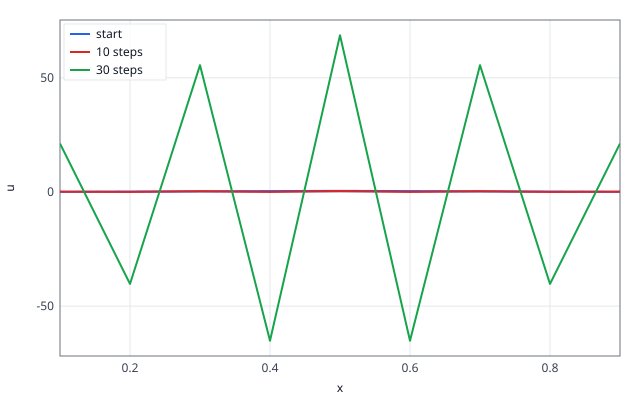

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [4]:
r = 3/5;
B = zeros(n - 1, n - 1);
for i = 1:n - 1
  B(i, i) = 1 - 2*r;
  if i > 1
    B(i, i - 1) = r;
  end
  if i < n - 1
    B(i, i + 1) = r;
  end
end
tent = (1 - abs(2*xs - 1))/2;
p = legend(plot(xs, tent), "start");
p = show(p, legend(plot(xs, tent * B^10), "10 steps"));
p = show(p, legend(plot(xs, tent * B^30), "30 steps"));
labels(p, "x", "u")

After 30 steps the temperature zigzags between huge positive and negative values: nonsense, since heat cannot create
temperatures hotter than where it started. The culprit is the fastest-wiggling pattern $(+, -, +, -, \dots)$. One
step multiplies it by about $1 - 4r$, which for $r = 3/5$ is $-1.4$: every step flips it and makes it 40% bigger.
Tiny rounding errors and the corner of the tent contain a little of this pattern, and it grows exponentially. The
eigenvalues of the step matrix tell the story; one of them is below $-1$:

In [5]:
eval(eig(B), 3)

[-1.34, -1.17, -0.905, -0.571, -0.200, 0.171, 0.505, 0.771, 0.941]

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

For a scheme to be **stable**, every eigenvalue must lie between $-1$ and $1$. Here they are
$1 - 4r\sin^2\!\big(\tfrac{j\pi}{2n}\big)$, so the explicit scheme is stable exactly when

$$r = \frac{k\,\Delta t}{h^2} \le \frac12.$$

That is a severe limit: halve $h$ for more accuracy and you must take four times as many time steps. John Crank and
Phyllis Nicolson found the way out in 1947: average the second difference over the old and the new time. Each step
then needs a (cheap) linear solve, but the scheme is stable for every $\Delta t$.

**Try this.** Compute `eval(eig(A), 3)` for the matrix of section 1 ($r = 2/5$). Are all eigenvalues between $-1$ and
$1$? Which eigenvalue is the slowest to die out, and which pattern does it belong to?

## 3. Crank–Nicolson with `heat`

`heat(f, x, a, b, T)` solves $u_t = u_{xx}$ on $a \le x \le b$ up to time $T$, starting from $u = f(x)$ with $u = 0$ at
both ends, by Crank–Nicolson on 100 pieces. It returns a record: `x` holds the grid, `t` the times of 51 snapshots,
and `u` one row per snapshot. `pdeplot` shows it. Start from a smooth hump plus a fast wiggle:

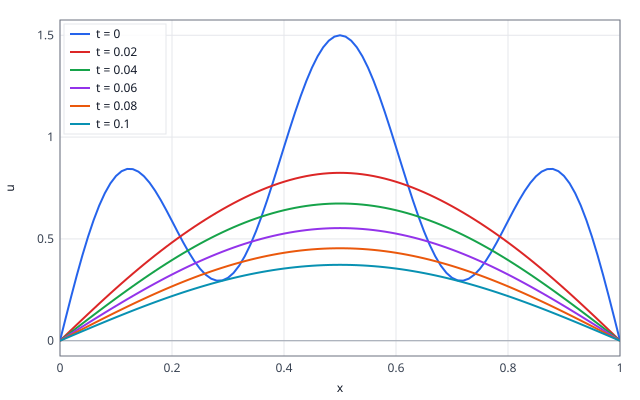

> pdeplot: u against x at 6 values of t.

In [6]:
s = heat(sin(pi*x) + 0.5*sin(5*pi*x), x, 0, 1, 0.1);
pdeplot(s, "lines")

The wiggle is gone almost at once while the hump shrinks slowly. Fourier explains why: the pattern $\sin(m\pi x)$
decays like $e^{-m^2\pi^2 t}$, so the fifth one dies 25 times faster than the first. Heat smooths. That is also why
running the heat equation backwards in time (un-blurring a photo) is so hard: it would have to blow up the wiggles.
The whole history fits in one picture, with $x$ across and time upwards:

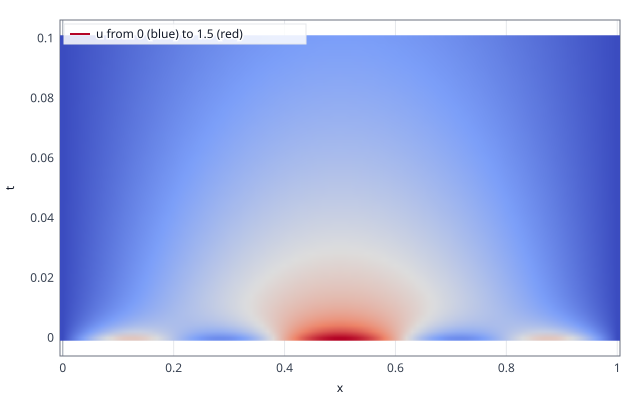

> pdeplot: the whole history as colors, x across and time t upward; blue is low, red is high.

In [7]:
pdeplot(s, "map")

Compare the computed final temperature with Fourier's exact solution
$e^{-\pi^2 t}\sin(\pi x) + \tfrac12 e^{-25\pi^2 t}\sin(5\pi x)$ at $x = 1/2$ (grid point 51):

In [8]:
U = s.u;
final = U(end);
eval(final(51), 6)
eval(exp(-pi^2*0.1) - 0.5*exp(-25*pi^2*0.1), 6)

0.372738

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

0.372708

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

**Try this.** The wiggle starts with amplitude $1/2$. At what time has it dropped below $0.005$? Solve
$\tfrac12 e^{-25\pi^2 t} = 0.005$, then check with `pdeplot(heat(0.5*sin(5*pi*x), x, 0, 1, 0.03), "lines")`.

## 4. Ends, steady states and heat sources

A last argument, a record of options, changes the set-up. `k` sets the diffusivity, `left` and `right` set the ends:
a temperature, an expression in $t$, or `"insulated"` (no heat flows through, $u_x = 0$). Hold the left end of a cold
rod at temperature 1 and insulate the right end:

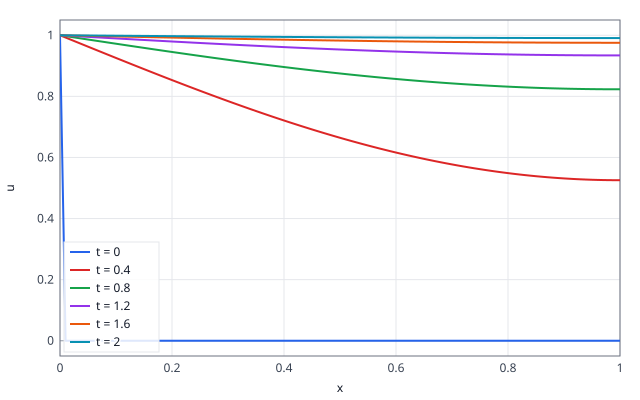

> pdeplot: u against x at 6 values of t.

In [9]:
s = heat(0, x, 0, 1, 2, {left: 1, right: "insulated"});
pdeplot(s, "lines")

Heat flows in from the left and, with nowhere to go, the whole rod slowly warms up to 1. The **steady state** is the
solution that no longer changes: $u_t = 0$, so $u_{xx} = 0$ and $u$ is a straight line. With both ends fixed, at 1
and 3 on a rod of length 2, it is the line from 1 to 3; at the middle point it is 2:

In [10]:
s = heat(0, x, 0, 2, 20, {left: 1, right: 3});
U = s.u;
final = U(end);
eval(final(51), 6)

2.00000

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

A **source** adds heat inside the rod, as an electric current does in a wire: $u_t = u_{xx} + q(x, t)$. With
$q = 2$ and both ends at 0, the steady state solves $u'' = -2$, which is $u = x(1 - x)$:

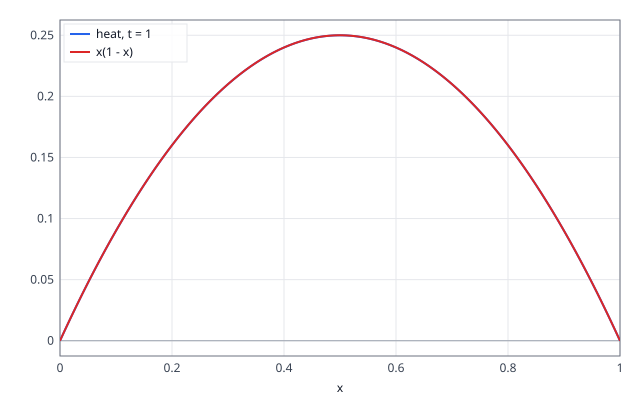

> `show`: Overlays plots: all 2D, or all 3D.

In [11]:
s = heat(0, x, 0, 1, 1, {source: 2});
U = s.u;
final = U(end);
p = legend(plot(s.x, final), "heat, t = 1");
show(p, legend(plot(x*(1 - x), x, 0, 1), "x(1 - x)"))

**Try this.** A wire carries a current that heats it at rate $q = 1$, and both its ends are kept at 0. What is its
steady temperature, and its highest value? Check with `heat`.

## 5. Fourier's series solution

Fourier solved the heat equation for *any* starting temperature $f(x)$ on $[0, 1]$ with ends at 0 by writing $f$ as a
sum of sines, $f(x) = \sum_m b_m \sin(m\pi x)$ with $b_m = 2\int_0^1 f(x)\sin(m\pi x)\,dx$. Each sine then decays on
its own:

$$u(x, t) = \sum_{m=1}^{\infty} b_m\, e^{-m^2\pi^2 t} \sin(m\pi x).$$

For the parabola $f = x(1 - x)$:

In [12]:
integrate(2*x*(1 - x)*sin(m*pi*x), x, 0, 1)

(4-2*pi*m*sin(pi*m)-4*cos(pi*m))/(pi^3*m^3)

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

For whole numbers $m$, $\sin(m\pi) = 0$ and $\cos(m\pi) = (-1)^m$, so $b_m = 8/(m^3\pi^3)$ for odd $m$ and 0 for even
$m$. Three terms of the series at $x = 1/2$, $t = 0.05$, against `heat`:

In [13]:
f = 0;
for m = [1 3 5]
  f = f + 8/(m^3*pi^3) * exp(-m^2*pi^2*0.05) * sin(m*pi/2);
end
eval(f, 6)
s = heat(x*(1 - x), x, 0, 1, 0.05, {frames: 1});
U = s.u;
final = U(end);
eval(final(51), 6)

0.157403

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

0.157409

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

The terms shrink so fast that three of them are plenty: for $t > 0$ the series converges very quickly, because the
factors $e^{-m^2\pi^2 t}$ kill the high frequencies.

**Try this.** How many terms of the series do you need at $t = 0$, where there is no exponential help? Compare the sum
of the first three terms at $x = 1/2$ with $f(1/2) = 1/4$.

## Summary

* The heat equation $u_t = k u_{xx}$ says that a point warms when it is colder than the average of its neighbours.
* The explicit scheme $u_i \mathrel{+}= r(u_{i-1} - 2u_i + u_{i+1})$ is a matrix step; it is stable only for
  $r = k\Delta t/h^2 \le 1/2$. Unstable schemes blow up the fastest wiggle.
* Crank–Nicolson (`heat`) is stable for every time step. `pdeplot` shows the result as an animation, snapshots or a map.
* Ends can be held at a temperature or insulated; the steady state solves $u_{xx} = -q/k$.
* Fourier: $\sin(m\pi x)$ decays like $e^{-m^2\pi^2 k t}$, so heat smooths out wiggles first.

Next: [waves on a string](02-waves-on-a-string.ipynb), where wiggles do not die but travel.

## Exercises

1. **Diffusivity.** Copper has $k \approx 1.1 \cdot 10^{-4}\ \text{m}^2/\text{s}$. How long does the slowest pattern
   $\sin(\pi x/L)$ take to drop by a factor $e$ in a copper rod of length $L = 1$ m? (It decays like
   $e^{-\pi^2 k t/L^2}$.)
2. **Stable or not.** With $k = 1$ and $h = 1/50$, what is the largest stable time step for the explicit scheme? How
   many steps does it take to reach $t = 1$?
3. **Cooling from both ends.** A rod at temperature 1 has both ends suddenly put on ice (temperature 0). Use `heat` with
   $f = 1$ and find the temperature in the middle at $t = 0.1$. Compare with the first term of Fourier's series,
   $\tfrac{4}{\pi} e^{-\pi^2 t}$.
4. **A day and a night.** The left end of a rod follows the day, `left: sin(2*pi*t)`, and the right end is insulated.
   Run `heat(0, x, 0, 1, 3, {left: sin(2*pi*t), right: "insulated"})` and look at the map. How does the swing at the
   far end compare with the swing at the heated end? (This is why cellars keep an even temperature.)
5. **Total heat.** With both ends insulated, the total heat $\int_0^1 u\,dx$ cannot change. Check it with `heat(x, x,
   0, 1, 1, {left: "insulated", right: "insulated"})`: what does the rod settle to?

## Hints and answers

* **Section 1, Try this.** With $n = 20$ the peak is about $0.3717$ against $0.3727$, an error of about $0.0011$
  instead of about $0.0043$ with $n = 10$: four times smaller, as expected for a method whose error is proportional
  to $h^2$.
* **Section 2, Try this.** All nine eigenvalues lie between $-0.57$ and $0.96$, so the scheme is stable. The slowest to
  die is the largest, $1 - 4r\sin^2(\pi/20) \approx 0.961$, belonging to the smooth hump $\sin(\pi x)$; the most
  negative, $-0.56$, belongs to the zigzag.
* **Section 3, Try this.** $t = \ln(100)/(25\pi^2) \approx 0.0187$.
* **Section 4, Try this.** $u = x(1 - x)/2$, from $u'' = -1$; its highest value is $1/8$ in the middle.
* **Section 5, Try this.** $\tfrac{8}{\pi^3}(1 - \tfrac1{27} + \tfrac1{125}) \approx 0.2505$, already within 0.2% of
  $1/4$: the coefficients fall like $1/m^3$ because the parabola is smooth. A shape with corners, like the tent, has
  coefficients falling only like $1/m^2$ and needs more terms.
* **Exercise 1.** $L^2/(\pi^2 k) \approx 920$ s, about a quarter of an hour.
* **Exercise 2.** $\Delta t \le h^2/2 = 1/5000$, so 5000 steps.
* **Exercise 3.** About $0.4745$; the first term gives $\tfrac4\pi e^{-0.1\pi^2} \approx 0.4745$ as well. The next
  term, $-\tfrac{4}{3\pi}e^{-0.9\pi^2} \approx -0.00006$, is tiny.
* **Exercise 4.** Once the start-up has passed, the far end swings about a third as much and lags behind: the daily wave is damped as it
  diffuses into the rod.
* **Exercise 5.** The rod settles to the average starting temperature, $1/2$, everywhere.

## Sources

1. J. Fourier, *Théorie analytique de la chaleur*, Firmin Didot (1822); English translation *The Analytical Theory of
   Heat*, Cambridge University Press (1878).
2. J. Crank and P. Nicolson, "A practical method for numerical evaluation of solutions of partial differential
   equations of the heat-conduction type", *Proceedings of the Cambridge Philosophical Society* 43 (1947), 50–67.
3. W. A. Strauss, *Partial Differential Equations: An Introduction*, 2nd ed., Wiley (2008), chapters 2 and 8.
4. R. J. LeVeque, *Finite Difference Methods for Ordinary and Partial Differential Equations*, SIAM (2007), chapter 9
   (stability of the heat equation schemes).